In [ ]:
import sys
import time
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Подключаем корневую папку проекта, чтобы импортировать настройки из src/config.py
sys.path.insert(0, str(Path.cwd().parent))
from src.config import INTERIM_DIR, RAW_FILES, REVIEW_SAMPLE_PATH

# 1. Читаем наш срез отзывов (200 000 строк) и таблицу заведений (business)
# Параметр lines=True указывает, что каждая строка файла — это отдельный JSON-объект
df_reviews = pd.read_json(REVIEW_SAMPLE_PATH, lines=True)
df_business = pd.read_json(RAW_FILES["business"], lines=True)

print("Размер таблицы отзывов (строк, столбцов):", df_reviews.shape)
display(df_reviews.head(3))

print("Размер таблицы заведений (строк, столбцов):", df_business.shape)
display(df_business.head(3))

Размер таблицы отзывов (строк, столбцов): (200000, 9)


,review_id,user_id,business_id,stars,useful,funny,cool,text,date
0,KU_O5udG6zpxOg-VcAEodg,mh_-eMZ6K5RLWhZyISBhwA,XQfwVwDr-v0ZS3_CbbE5Xw,3,0,0,0,"If you decide to eat here, just be aware it is...",2018-07-07 22:09:11
1,BiTunyQ73aT9WBnpR9DZGw,OyoGAe7OKpv6SyGZT5g77Q,7ATYjTIgM3jUlt4UM3IypQ,5,1,0,1,I've taken a lot of spin classes over the year...,2012-01-03 15:28:18
2,saUsX_uimxRlCVr67Z4Jig,8g_iMtfSiwikVnbP2etR0A,YjUWPpI6HXG530lwP-fb2A,3,0,0,0,Family diner. Had the buffet. Eclectic assortm...,2014-02-05 20:30:30


Размер таблицы заведений (строк, столбцов): (150346, 14)


,business_id,name,address,city,state,postal_code,latitude,longitude,stars,review_count,is_open,attributes,categories,hours
0,Pns2l4eNsfO8kk83dixA6A,"Abby Rappoport, LAC, CMQ","1616 Chapala St, Ste 2",Santa Barbara,CA,93101,34.426679,-119.711197,5.0,7,0,{'ByAppointmentOnly': 'True'},"Doctors, Traditional Chinese Medicine, Naturop...",None
1,mpf3x-BjTdTEA3yCZrAYPw,The UPS Store,87 Grasso Plaza Shopping Center,Affton,MO,63123,38.551126,-90.335695,3.0,15,1,{'BusinessAcceptsCreditCards': 'True'},"Shipping Centers, Local Services, Notaries, Ma...","{'Monday': '0:0-0:0', 'Tuesday': '8:0-18:30', ..."
2,tUFrWirKiKi_TAnsVWINQQ,Target,5255 E Broadway Blvd,Tucson,AZ,85711,32.223236,-110.880452,3.5,22,0,"{'BikeParking': 'True', 'BusinessAcceptsCredit...","Department Stores, Shopping, Fashion, Home & G...","{'Monday': '8:0-22:0', 'Tuesday': '8:0-22:0', ..."


In [5]:
# 1. Собираем сводную таблицу по каждому столбцу среза отзывов
review_summary = pd.DataFrame({
    "Тип данных": df_reviews.dtypes,
    "Уникальных значений": df_reviews.nunique(),
    "Пропусков (шт)": df_reviews.isna().sum(),
    "Доля пропусков (%)": (df_reviews.isna().mean() * 100).round(2)
})
print("=== Сводка по столбцам таблицы отзывов (review) ===")
display(review_summary)

# 2. Собираем сводную таблицу по каждому столбцу справочника заведений
# Переводим в str для подсчёта уникальных, так как в attributes и hours лежат словари
business_summary = pd.DataFrame({
    "Тип данных": df_business.dtypes,
    "Уникальных значений": df_business.astype(str).nunique(),
    "Пропусков (шт)": df_business.isna().sum(),
    "Доля пропусков (%)": (df_business.isna().mean() * 100).round(2)
})
print("=== Сводка по столбцам таблицы заведений (business) ===")
display(business_summary)

# 3. Проверяем типовые дефекты для отчёта:
# Дефект А: сколько городов дублируется из-за разного регистра (Tampa vs tampa) и пробелов
cities_before = df_business["city"].nunique()
cities_after = df_business["city"].str.strip().str.lower().nunique()
print(f"Уникальных городов до очистки: {cities_before}, после очистки регистра: {cities_after}")
print(f"Найдено дублей названий городов: {cities_before - cities_after}")

# Дефект Б: сколько скрытых пропусков (пустых строк "") в адресах заведений
empty_addr = (df_business["address"] == "").sum()
print(f"Скрытых пропусков (пустых строк '') в столбце address: {empty_addr}")

=== Сводка по столбцам таблицы отзывов (review) ===


,Тип данных,Уникальных значений,Пропусков (шт),Доля пропусков (%)
review_id,str,200000,0,0.0
user_id,str,143686,0,0.0
business_id,str,11451,0,0.0
stars,int64,5,0,0.0
useful,int64,59,0,0.0
funny,int64,38,0,0.0
cool,int64,40,0,0.0
text,str,199816,0,0.0
date,datetime64[us],199818,0,0.0


=== Сводка по столбцам таблицы заведений (business) ===


,Тип данных,Уникальных значений,Пропусков (шт),Доля пропусков (%)
business_id,str,150346,0,0.00
name,str,114117,0,0.00
address,str,122844,0,0.00
city,str,1416,0,0.00
state,str,27,0,0.00
postal_code,str,3362,0,0.00
latitude,float64,135593,0,0.00
longitude,float64,131918,0,0.00
stars,float64,9,0,0.00
review_count,int64,1158,0,0.00


Уникальных городов до очистки: 1416, после очистки регистра: 1238
Найдено дублей названий городов: 178
Скрытых пропусков (пустых строк '') в столбце address: 5127


=== Таблица 6: Сравнение форматов хранения данных ===


,Формат,"Объём, МБ","Запись, с","Чтение, с",Отношение к CSV (по объёму)
0,CSV (исходный),124.07,3.429,0.258,1.00
1,Pickle,131.15,0.353,0.057,1.06
2,Feather,85.16,1.297,0.117,0.69
3,Parquet (snappy),78.17,0.658,0.239,0.63
4,"Parquet, 3 столбца",78.17,-,0.016,0.63


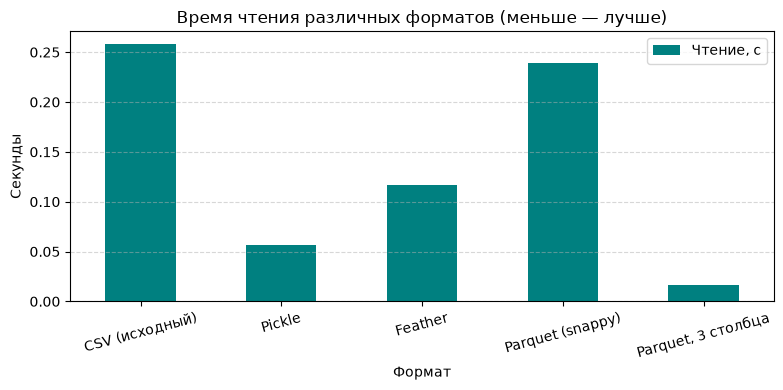

In [6]:
# Задаём пути для сохранения одного и того же набора в 4 разных форматах
csv_path = INTERIM_DIR / "test_format.csv"
pkl_path = INTERIM_DIR / "test_format.pkl"
ftr_path = INTERIM_DIR / "test_format.feather"
pq_path = INTERIM_DIR / "test_format.parquet"

# 1. Измеряем время записи (сериализации) в секундах для каждого формата
t0 = time.perf_counter()
df_reviews.to_csv(csv_path, index=False)
write_csv = time.perf_counter() - t0

t0 = time.perf_counter()
df_reviews.to_pickle(pkl_path)
write_pkl = time.perf_counter() - t0

t0 = time.perf_counter()
df_reviews.to_feather(ftr_path)
write_ftr = time.perf_counter() - t0

t0 = time.perf_counter()
df_reviews.to_parquet(pq_path, compression="snappy", index=False)
write_pq = time.perf_counter() - t0

# 2. Измеряем время чтения (десериализации)
t0 = time.perf_counter()
pd.read_csv(csv_path)
read_csv = time.perf_counter() - t0

t0 = time.perf_counter()
pd.read_pickle(pkl_path)
read_pkl = time.perf_counter() - t0

t0 = time.perf_counter()
pd.read_feather(ftr_path)
read_ftr = time.perf_counter() - t0

t0 = time.perf_counter()
pd.read_parquet(pq_path)
read_pq = time.perf_counter() - t0

# Отдельно замеряем чтение только 3 столбцов из колоночного формата Parquet
t0 = time.perf_counter()
pd.read_parquet(pq_path, columns=["review_id", "stars", "date"])
read_pq_3cols = time.perf_counter() - t0

# 3. Вычисляем размер каждого файла на диске в мегабайтах
mb_csv = csv_path.stat().st_size / (1024 * 1024)
mb_pkl = pkl_path.stat().st_size / (1024 * 1024)
mb_ftr = ftr_path.stat().st_size / (1024 * 1024)
mb_pq = pq_path.stat().st_size / (1024 * 1024)

# 4. Собираем итоговую Таблицу 6 (по форме из методички, стр. 43)
table_6 = pd.DataFrame([
    {"Формат": "CSV (исходный)", "Объём, МБ": round(mb_csv, 2), "Запись, с": round(write_csv, 3), "Чтение, с": round(read_csv, 3), "Отношение к CSV (по объёму)": 1.00},
    {"Формат": "Pickle", "Объём, МБ": round(mb_pkl, 2), "Запись, с": round(write_pkl, 3), "Чтение, с": round(read_pkl, 3), "Отношение к CSV (по объёму)": round(mb_pkl / mb_csv, 2)},
    {"Формат": "Feather", "Объём, МБ": round(mb_ftr, 2), "Запись, с": round(write_ftr, 3), "Чтение, с": round(read_ftr, 3), "Отношение к CSV (по объёму)": round(mb_ftr / mb_csv, 2)},
    {"Формат": "Parquet (snappy)", "Объём, МБ": round(mb_pq, 2), "Запись, с": round(write_pq, 3), "Чтение, с": round(read_pq, 3), "Отношение к CSV (по объёму)": round(mb_pq / mb_csv, 2)},
    {"Формат": "Parquet, 3 столбца", "Объём, МБ": round(mb_pq, 2), "Запись, с": "-", "Чтение, с": round(read_pq_3cols, 3), "Отношение к CSV (по объёму)": round(mb_pq / mb_csv, 2)},
])

print("=== Таблица 6: Сравнение форматов хранения данных ===")
display(table_6)

# 5. Строим наглядную столбчатую диаграмму времени чтения
table_6.plot(x="Формат", y="Чтение, с", kind="bar", color="teal", figsize=(8, 4), title="Время чтения различных форматов (меньше — лучше)")
plt.ylabel("Секунды")
plt.xticks(rotation=15)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [7]:
# Присоединяем к отзывам город, штат и флаг открытия из таблицы заведений
df_untyped = df_reviews.merge(
    df_business[["business_id", "city", "state", "is_open"]],
    on="business_id",
    how="left"
)

untyped_path = INTERIM_DIR / "source_untyped.parquet"
typed_path = INTERIM_DIR / "source_typed.parquet"
df_untyped.to_parquet(untyped_path, index=False)

# 1. Проверяем долю уникальных значений в текстовых столбцах (если < 50%, выгодно перевести в category)
print("Доля уникальных значений в текстовых столбцах:")
for col in ["review_id", "city", "state", "text"]:
    unique_share = (df_untyped[col].nunique() / len(df_untyped)) * 100
    print(f" -> Столбец {col}: {unique_share:.3f}% уникальных")

# 2. Замеряем показатели ДО оптимизации типов
mem_before = df_untyped.memory_usage(deep=True).sum() / (1024 * 1024)
disk_before = untyped_path.stat().st_size / (1024 * 1024)

t0 = time.perf_counter()
pd.read_parquet(untyped_path)
read_before = time.perf_counter() - t0

t0 = time.perf_counter()
df_untyped.groupby("state")["stars"].mean()
group_before = time.perf_counter() - t0

# 3. Назначаем каждому столбцу оптимальный тип данных по предметной области
optimal_types = {
    "review_id": "string",
    "user_id": "string",
    "business_id": "string",
    "stars": "int8",          # Оценка от 1 до 5 (1 байт вместо 8 байт)
    "useful": "int16",        # Счётчик голосов до 32 767 (2 байта вместо 8 байт)
    "funny": "int16",
    "cool": "int16",
    "text": "string",         # Длинный уникальный текст — оставляем строкой
    "city": "category",       # Города часто повторяются — переводим в категорию
    "state": "category",      # Штатов всего несколько десятков — переводим в категорию
    "is_open": "boolean"      # Флаг 0/1 — переводим в логический тип (1 байт)
}

df_typed = df_untyped.astype(optimal_types)
# Дату обязательно переводим из текста в тип datetime
df_typed["date"] = pd.to_datetime(df_typed["date"])
df_typed.to_parquet(typed_path, index=False)

# 4. Замеряем показатели ПОСЛЕ оптимизации типов
mem_after = df_typed.memory_usage(deep=True).sum() / (1024 * 1024)
disk_after = typed_path.stat().st_size / (1024 * 1024)

t0 = time.perf_counter()
pd.read_parquet(typed_path)
read_after = time.perf_counter() - t0

t0 = time.perf_counter()
df_typed.groupby("state", observed=True)["stars"].mean()
group_after = time.perf_counter() - t0

# 5. Выводим Таблицу 7 (по форме из методички, стр. 44)
table_7 = pd.DataFrame([
    {"Показатель": "Объём файла на диске, МБ", "До оптимизации": round(disk_before, 2), "После": round(disk_after, 2), "Изменение": f"-{round((1 - disk_after/disk_before)*100, 1)}%"},
    {"Показатель": "Объём в памяти, МБ", "До оптимизации": round(mem_before, 2), "После": round(mem_after, 2), "Изменение": f"-{round((1 - mem_after/mem_before)*100, 1)}%"},
    {"Показатель": "Время чтения, с", "До оптимизации": round(read_before, 3), "После": round(read_after, 3), "Изменение": f"быстрее в {round(read_before/read_after, 2)} раза"},
    {"Показатель": "Время группировки, с", "До оптимизации": round(group_before, 4), "После": round(group_after, 4), "Изменение": f"быстрее в {round(group_before/group_after, 2)} раза"},
    {"Показатель": "Число столбцов типа category", "До оптимизации": 0, "После": 2, "Изменение": "+2 (city, state)"},
])

print("\n=== Таблица 7: Результаты оптимизации схемы данных ===")
display(table_7)

Доля уникальных значений в текстовых столбцах:
 -> Столбец review_id: 100.000% уникальных
 -> Столбец city: 0.285% уникальных
 -> Столбец state: 0.009% уникальных
 -> Столбец text: 99.908% уникальных

=== Таблица 7: Результаты оптимизации схемы данных ===


,Показатель,До оптимизации,После,Изменение
0,"Объём файла на диске, МБ",78.5600,78.5600,--0.0%
1,"Объём в памяти, МБ",138.0100,127.3400,-7.7%
2,"Время чтения, с",0.2520,0.2310,быстрее в 1.09 раза
3,"Время группировки, с",0.0077,0.0072,быстрее в 1.08 раза
4,Число столбцов типа category,0.0000,2.0000,"+2 (city, state)"


=== Таблица 8: Сравнение скорости pandas и polars ===


,Операция,"pandas, с","polars, с",Ускорение (раз)
0,Чтение Parquet,0.2458,0.2853,0.86
1,Фильтрация,0.0530,0.0109,4.86
2,Группировка и агрегирование,0.0194,0.0063,3.10
3,Сортировка,0.0871,0.0159,5.49
4,Соединение таблиц,0.0852,0.0118,7.21
5,Цепочка операций (ленивый режим),0.2957,0.0102,28.86


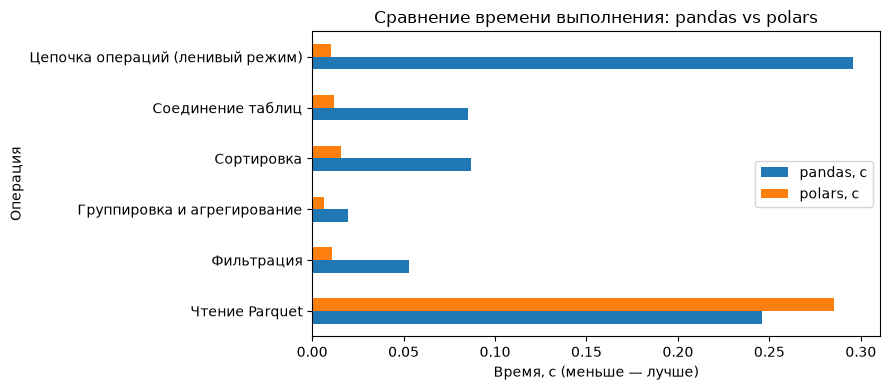

In [8]:
import polars as pl

# Сохраним небольшой справочник заведений в Parquet для проверки операции соединения (JOIN)
biz_small_path = INTERIM_DIR / "business_small.parquet"
df_business[["business_id", "name", "review_count"]].to_parquet(biz_small_path, index=False)

# 1. Операция: Чтение Parquet-файла
t0 = time.perf_counter()
pd_data = pd.read_parquet(untyped_path)
t_pd_read = time.perf_counter() - t0

t0 = time.perf_counter()
pl_data = pl.read_parquet(untyped_path)
t_pl_read = time.perf_counter() - t0

pd_biz = pd.read_parquet(biz_small_path)
pl_biz = pl.read_parquet(biz_small_path)

# 2. Операция: Фильтрация строк (отзывы с оценкой >= 4 и полезностью > 0)
t0 = time.perf_counter()
_ = pd_data[(pd_data["stars"] >= 4) & (pd_data["useful"] > 0)]
t_pd_filter = time.perf_counter() - t0

t0 = time.perf_counter()
_ = pl_data.filter((pl.col("stars") >= 4) & (pl.col("useful") > 0))
t_pl_filter = time.perf_counter() - t0

# 3. Операция: Группировка по городу и расчёт медианы голосов useful
t0 = time.perf_counter()
_ = pd_data.groupby("city")["useful"].median()
t_pd_group = time.perf_counter() - t0

t0 = time.perf_counter()
_ = pl_data.group_by("city").agg(pl.col("useful").median())
t_pl_group = time.perf_counter() - t0

# 4. Операция: Сортировка таблицы по убыванию голосов useful
t0 = time.perf_counter()
_ = pd_data.sort_values(by="useful", ascending=False)
t_pd_sort = time.perf_counter() - t0

t0 = time.perf_counter()
_ = pl_data.sort("useful", descending=True)
t_pl_sort = time.perf_counter() - t0

# 5. Операция: Соединение двух таблиц по ключу business_id (LEFT JOIN)
t0 = time.perf_counter()
_ = pd_data.merge(pd_biz, on="business_id", how="left")
t_pd_join = time.perf_counter() - t0

t0 = time.perf_counter()
_ = pl_data.join(pl_biz, on="business_id", how="left")
t_pl_join = time.perf_counter() - t0

# 6. Цепочка операций целиком: обычный pandas против ленивого режима polars (scan_parquet)
t0 = time.perf_counter()
_ = (
    pd.read_parquet(untyped_path)
    .query("useful > 0")
    .groupby("city")["stars"]
    .median()
    .sort_values(ascending=False)
)
t_pd_chain = time.perf_counter() - t0

t0 = time.perf_counter()
_ = (
    pl.scan_parquet(untyped_path)
    .filter(pl.col("useful") > 0)
    .group_by("city")
    .agg(pl.col("stars").median())
    .sort("stars", descending=True)
    .collect()  # Команда collect() запускает оптимизированный план запроса
)
t_pl_chain = time.perf_counter() - t0

# Собираем Таблицу 8 (по форме из методички, стр. 44-45)
table_8 = pd.DataFrame([
    {"Операция": "Чтение Parquet", "pandas, с": round(t_pd_read, 4), "polars, с": round(t_pl_read, 4), "Ускорение (раз)": round(t_pd_read / t_pl_read, 2)},
    {"Операция": "Фильтрация", "pandas, с": round(t_pd_filter, 4), "polars, с": round(t_pl_filter, 4), "Ускорение (раз)": round(t_pd_filter / t_pl_filter, 2)},
    {"Операция": "Группировка и агрегирование", "pandas, с": round(t_pd_group, 4), "polars, с": round(t_pl_group, 4), "Ускорение (раз)": round(t_pd_group / t_pl_group, 2)},
    {"Операция": "Сортировка", "pandas, с": round(t_pd_sort, 4), "polars, с": round(t_pl_sort, 4), "Ускорение (раз)": round(t_pd_sort / t_pl_sort, 2)},
    {"Операция": "Соединение таблиц", "pandas, с": round(t_pd_join, 4), "polars, с": round(t_pl_join, 4), "Ускорение (раз)": round(t_pd_join / t_pl_join, 2)},
    {"Операция": "Цепочка операций (ленивый режим)", "pandas, с": round(t_pd_chain, 4), "polars, с": round(t_pl_chain, 4), "Ускорение (раз)": round(t_pd_chain / t_pl_chain, 2)},
])

print("=== Таблица 8: Сравнение скорости pandas и polars ===")
display(table_8)

# Строим горизонтальный график для отчёта
table_8.plot(x="Операция", y=["pandas, с", "polars, с"], kind="barh", figsize=(9, 4), title="Сравнение времени выполнения: pandas vs polars")
plt.xlabel("Время, с (меньше — лучше)")
plt.tight_layout()
plt.show()